# CardioSense — Multimodal Fusion

Combines the three trained Phase 1 models into one confidence-aware assessment.

| modality | model | headline | calibrated? |
|---|---|---|---|
| Clinical | Logistic Regression (UCI) | ROC-AUC 0.964 | yes |
| ECG | features_xgb (PTB-XL + PTB-XL+) | macro AUC 0.941, macro F1 0.771 | no |
| X-ray | DenseNet121 (ChestX-ray14 subset) | PR-AUC 0.301 (chance 0.033), ROC-AUC 0.898 | no |

---

## What this notebook can and cannot show

**It can** demonstrate the fusion *mechanism*: that three heterogeneous models
can be mapped onto a common scale, weighted by how much each can be trusted,
combined when present and excluded when absent, and flagged when they conflict.

**It cannot** make a clinical accuracy claim. The three models are trained on
**three disjoint cohorts** with **three different targets** — no patient appears
in more than one. There is no dataset on which "fusion improves diagnostic
accuracy" can be measured for this system, and none is claimed here.

That is a real limitation, not a formality. State it before an examiner finds it.

## How each modality reaches a common scale

| modality | native output | mapped risk |
|---|---|---|
| clinical | P(stenosis >50%) | used directly, calibrated |
| ECG | 5 superclass probabilities | `1 - P(NORM)` |
| X-ray | P(cardiomegaly) | prior-corrected to population prevalence |

`1 - P(NORM)` rather than a maximum over abnormal classes, because NORM is an
explicitly trained class — it is the model's own estimate that the trace is not
normal, not an ad-hoc aggregation over classes that were never meant to be
pooled.

## Confidence

```
confidence = reliability x decisiveness
```

* **reliability** = `1 - ECE/0.25` on held-out data. Model-level, and capped at
  **0.50** for any modality that was never calibrated.
* **decisiveness** = `|2p - 1|`. Case-specific: how far this one prediction is
  from a coin flip.

Both terms are needed and each blocks a different failure. Without reliability
an overconfident model dominates — and `pos_weight` training pushes the X-ray
model toward extreme outputs by construction. Without decisiveness the fusion
cannot adapt per patient.

## 1. Environment

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/CardioSense")
PROJECT_ROOT = Path("/content/CardioSense")
MODELS_ROOT = DRIVE_ROOT / "models"

XRAY_DIR = DRIVE_ROOT / "data" / "xray" / "nih" / "images"
ECG_DIR = DRIVE_ROOT / "data" / "ptbxl_plus"

assert DRIVE_ROOT.exists(), f"CardioSense folder not found: {DRIVE_ROOT}"
assert XRAY_DIR.exists(), f"X-ray directory not found: {XRAY_DIR}"
assert ECG_DIR.exists(), f"ECG directory not found: {ECG_DIR}"

print("Drive project:", DRIVE_ROOT)
print("X-ray directory:", XRAY_DIR)
print("ECG directory:", ECG_DIR)

Mounted at /content/drive
Drive project: /content/drive/MyDrive/CardioSense
X-ray directory: /content/drive/MyDrive/CardioSense/data/xray/nih/images
ECG directory: /content/drive/MyDrive/CardioSense/data/ptbxl_plus


In [34]:
from pathlib import Path
import shutil
import time

DRIVE_REPO = Path("/content/drive/MyDrive/CardioSense")
LOCAL_REPO = Path("/content/CardioSense")

assert (DRIVE_REPO / "pyproject.toml").exists(), "Drive project not found"

# Copy code and configuration, but avoid duplicating large datasets and models
LOCAL_REPO.mkdir(parents=True, exist_ok=True)

for folder in ["src", "configs", "notebooks", "scripts", "tests", "docs"]:
    source = DRIVE_REPO / folder
    destination = LOCAL_REPO / folder

    if source.exists():
        shutil.copytree(source, destination, dirs_exist_ok=True)
        print(f"Restored: {folder}")

for filename in [
    "pyproject.toml",
    "requirements.txt",
    "requirements-colab.txt",
    "README.md",
    ".gitignore",
]:
    source = DRIVE_REPO / filename
    if source.exists():
        shutil.copy2(source, LOCAL_REPO / filename)

# Keep large files on Drive
for folder in ["data", "models", "results"]:
    destination = LOCAL_REPO / folder
    source = DRIVE_REPO / folder

    if source.exists() and not destination.exists():
        destination.symlink_to(source, target_is_directory=True)
        print(f"Linked to Drive: {folder}")

print("\nRepository restored:", LOCAL_REPO)
print("pyproject exists:", (LOCAL_REPO / "pyproject.toml").exists())
print("source exists:", (LOCAL_REPO / "src" / "cardiosense").exists())

Restored: src
Restored: configs
Restored: notebooks
Restored: scripts
Restored: tests
Restored: docs

Repository restored: /content/CardioSense
pyproject exists: True
source exists: True


In [35]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_DIR = Path("/content/CardioSense")
DRIVE = Path("/content/drive/MyDrive/CardioSense")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    if not REPO_DIR.exists():
        raise RuntimeError(
            f"{REPO_DIR} not found. Clone your repo first — this notebook does "
            "not clone, so a rerun cannot replace your working copy.")
    os.chdir(REPO_DIR)
    os.environ["CARDIOSENSE_DATA_ROOT"] = str(DRIVE / "data")
    subprocess.run(["pip", "install", "-q", "-e", "."], check=False)
else:
    here = Path.cwd()
    while not (here / "pyproject.toml").exists() and here != here.parent:
        here = here.parent
    os.chdir(here); REPO_DIR = here

src = str(REPO_DIR / "src")
if src not in sys.path:
    sys.path.insert(0, src)

MODELS_ROOT = DRIVE / "models" if IN_COLAB else REPO_DIR / "models"
RESULTS = (DRIVE / "results" if IN_COLAB else REPO_DIR / "results") / "fusion"
RESULTS.mkdir(parents=True, exist_ok=True)

print("repo    :", REPO_DIR)
print("models  :", MODELS_ROOT)
print("results :", RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
repo    : /content/CardioSense
models  : /content/drive/MyDrive/CardioSense/models
results : /content/drive/MyDrive/CardioSense/results/fusion


## 2. Load the three adapters

Each adapter wraps one trained model **without modifying it** and returns a
standardised `ModalityPrediction`.

A failure to load is recorded, never raised. A decision-support system that
refuses to start because one model is absent is less useful than one that says
which inputs it had.

In [36]:
from google.colab import files

uploaded = files.upload()
print(list(uploaded.keys()))

Saving CardioSense-phase2-fusion-rag final.zip to CardioSense-phase2-fusion-rag final (1).zip
['CardioSense-phase2-fusion-rag final (1).zip']


In [37]:
from pathlib import Path
import zipfile
import shutil
import sys

ZIP_PATH = Path("/content/CardioSense/CardioSense-phase2-fusion-rag final.zip")
EXTRACT_DIR = Path("/content/phase2_extract")
REPO = Path("/content/CardioSense")
DRIVE_REPO = Path("/content/drive/MyDrive/CardioSense")

assert ZIP_PATH.exists(), "The ZIP was not uploaded under the expected filename."

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)

PACKAGE = EXTRACT_DIR / "cardiosense_phase2"

print("Extracted folders:", [p.name for p in EXTRACT_DIR.iterdir()])
print("Package exists:", PACKAGE.exists())

Extracted folders: ['cardiosense_phase2']
Package exists: True


In [38]:
from pathlib import Path
import shutil
import sys

EXTRACT_DIR = Path("/content/phase2_extract")
REPO = Path("/content/CardioSense")
DRIVE_REPO = Path("/content/drive/MyDrive/CardioSense")

PACKAGE = EXTRACT_DIR / "cardiosense_phase2"

# Locate the source package in the extracted ZIP.
candidates = list(PACKAGE.rglob("fusion/__init__.py"))
assert candidates, "Could not find fusion/__init__.py in the extracted ZIP."

SOURCE_ROOT = candidates[0].parent.parent
print("Phase 2 source directory:", SOURCE_ROOT)

for module in ["fusion", "rag"]:
    src = SOURCE_ROOT / module
    assert src.is_dir(), f"Missing module directory: {src}"

    for base in [
        REPO / "src" / "cardiosense",
        DRIVE_REPO / "src" / "cardiosense",
    ]:
        dst = base / module
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print("Restored:", dst)

# Make the local source importable.
SRC = str(REPO / "src")
if SRC not in sys.path:
    sys.path.insert(0, SRC)

print("\nFusion module exists:",
      (REPO / "src/cardiosense/fusion/__init__.py").exists())
print("RAG directory exists:",
      (REPO / "src/cardiosense/rag").is_dir())

Phase 2 source directory: /content/phase2_extract/cardiosense_phase2/src/cardiosense
Restored: /content/CardioSense/src/cardiosense/fusion
Restored: /content/drive/MyDrive/CardioSense/src/cardiosense/fusion
Restored: /content/CardioSense/src/cardiosense/rag
Restored: /content/drive/MyDrive/CardioSense/src/cardiosense/rag

Fusion module exists: True
RAG directory exists: True


In [39]:
import cardiosense

from cardiosense.fusion import (
    FusionEngine,
    ModalityPrediction,
    build_strategy,
    detect_disagreement,
    prior_correct,
    risk_level,
    RISK_DEFINITIONS,
)

print("Package:", cardiosense.__file__)
print("Fusion import successful.")

Package: /content/CardioSense/src/cardiosense/__init__.py
Fusion import successful.


In [40]:
from pathlib import Path
import shutil

adapter_file = Path(
    "/content/CardioSense/src/cardiosense/fusion/adapters.py"
)
backup_file = adapter_file.with_suffix(".py.bak")

source = adapter_file.read_text(encoding="utf-8")

old_helper = '''def _read_pickle(path: Path) -> Any:
    with open(path, "rb") as handle:
        return pickle.load(handle)
'''

new_helper = '''def _read_pickle(path: Path) -> Any:
    import joblib
    return joblib.load(path)
'''

if old_helper not in source:
    print("No changes made: helper did not match exactly.")
else:
    if not backup_file.exists():
        shutil.copy2(adapter_file, backup_file)

    source = source.replace(old_helper, new_helper, 1)
    adapter_file.write_text(source, encoding="utf-8")
    print("Patch applied successfully.")
    print("Backup:", backup_file)

Patch applied successfully.
Backup: /content/CardioSense/src/cardiosense/fusion/adapters.py.bak


In [41]:
import importlib
import cardiosense.fusion.adapters as adapters
from pathlib import Path

importlib.reload(adapters)

clinical = adapters.ClinicalAdapter(
    Path(MODELS_ROOT) / "clinical"
)

print("Available:", clinical.available)
print("Load error:", clinical.load_error)
print("Model loaded:", clinical.model is not None)
print("Preprocessor loaded:", clinical.preprocessor is not None)
print("Calibrator loaded:", clinical.calibrator is not None)

Available: True
Load error: 
Model loaded: True
Preprocessor loaded: True
Calibrator loaded: True


In [42]:
import shutil

shutil.copy2(
    "/content/CardioSense/src/cardiosense/fusion/adapters.py",
    "/content/drive/MyDrive/CardioSense/src/cardiosense/fusion/adapters.py"
)

print("Corrected adapter saved to Google Drive.")

Corrected adapter saved to Google Drive.


In [43]:
import json
import numpy as np
import pandas as pd

from cardiosense.fusion import (
    FusionEngine, ModalityPrediction, build_strategy,
    detect_disagreement, prior_correct, risk_level, RISK_DEFINITIONS,
)

engine = FusionEngine(MODELS_ROOT, strategy="confidence_logodds")
status = engine.status()

print(f"{'modality':<12}{'loaded':<9}{'calibrated':<13}{'reliability':<13}version")
print("-" * 70)
for name, s in status["adapters"].items():
    print(f"{name:<12}{str(s['available']):<9}{str(s['calibrated']):<13}"
          f"{s['reliability']:<13.3f}{s['model_version'][:28]}")
    if s["load_error"]:
        print(f"             -> {s['load_error'][:88]}")

print(f"\nready: {status['ready']}   degraded: {status['degraded']}")
if status["degraded"]:
    print("\nSome modalities could not be loaded. The engine still runs on what it\n"
          "has — that is the designed behaviour, not a failure.\n"
          "\nFor ECG specifically, three paths are tried in order and the version\n"
          "column above names whichever one loaded:\n"
          "  features_xgb   the model notebook 04 selected   (needs ecg_feature_model.pkl)\n"
          "  joint_gated    waveform + features               (needs the .pt + preprocessor)\n"
          "  signal_only    waveform alone                    (needs only the .pt files)\n"
          "\nIf none loaded: run 04b (same kernel as notebook 04) or 04c (cold start).")

modality    loaded   calibrated   reliability  version
----------------------------------------------------------------------
clinical    True     True         0.500        clinical-v0.1.0
ecg         True     False        0.500        ptbxl-plus-xgb-recovered
xray        True     False        0.500        xray-v0.1.0

ready: ['clinical', 'ecg', 'xray']   degraded: False


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:05:17] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:05:17] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:05:17] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:05:18] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:05:18] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: U

## 3. The mechanism, on worked examples

Before touching real inputs, exercise the fusion arithmetic directly. These are
constructed `ModalityPrediction` objects, so the behaviour is visible without
depending on any model loading.

In [44]:
def mp(name, risk, reliability=0.9, calibrated=True, **kw):
    return ModalityPrediction(modality=name, risk_score=risk,
                              reliability=reliability, is_calibrated=calibrated, **kw)

maths = FusionEngine(adapters={})      # no models needed for the arithmetic

cases = {
    "all three agree, high risk":
        [mp("clinical", 0.86), mp("ecg", 0.79), mp("xray", 0.81)],
    "clinical only (ECG and X-ray absent)":
        [mp("clinical", 0.86), ModalityPrediction.unavailable("ecg"),
         ModalityPrediction.unavailable("xray")],
    "ECG uncalibrated -> capped reliability":
        [mp("clinical", 0.86), mp("ecg", 0.79, 0.50, False), mp("xray", 0.81)],
    "ECG contradicts the other two":
        [mp("clinical", 0.92), mp("ecg", 0.04), mp("xray", 0.88)],
    "all unsure":
        [mp("clinical", 0.52, 0.6), mp("ecg", 0.48, 0.6), mp("xray", 0.51, 0.6)],
    "nothing available":
        [ModalityPrediction.unavailable(m) for m in ("clinical", "ecg", "xray")],
}

print(f"{'case':<40}{'risk':<9}{'level':<15}{'relia':<8}{'disagreement'}")
print("-" * 92)
for label, preds in cases.items():
    r = maths.fuse_predictions(preds)
    score = r.fused["risk_score"]
    shown = "  n/a" if score is None else f"{score:.3f}"
    print(f"{label:<40}{shown:<9}{r.fused['risk_level']:<15}"
          f"{r.fused['reliability']:<8.3f}{r.disagreement['severity']}")

case                                    risk     level          relia   disagreement
--------------------------------------------------------------------------------------------
all three agree, high risk              0.825    HIGH           0.906   NONE
clinical only (ECG and X-ray absent)    0.860    HIGH           0.593   NOT ASSESSABLE
ECG uncalibrated -> capped reliability  0.830    HIGH           0.850   NONE
ECG contradicts the other two           0.563    INTERMEDIATE   0.378   SEVERE
all unsure                              0.502    INTERMEDIATE   0.576   NONE
nothing available                         n/a    UNKNOWN        0.000   NOT ASSESSABLE


### The three invariants, checked rather than asserted

1. A missing modality carries **no weight** — it is excluded, never imputed.
2. A failing modality does not crash the assessment.
3. No modality available yields **UNKNOWN**, not a fabricated number.

In [45]:
r = maths.fuse_predictions(cases["clinical only (ECG and X-ray absent)"])
assert "ecg" not in r.fused["weights"] and "xray" not in r.fused["weights"]
assert abs(r.fused["risk_score"] - 0.86) < 1e-9
print("1. missing modality carries no weight; single score passes through   OK")
print("   weights:", r.fused["weights"], "| missing:", r.availability["missing"])

r = maths.fuse_predictions([
    mp("clinical", 0.86),
    ModalityPrediction.failed_inference("ecg", "corrupt .npy"),
    mp("xray", 0.77)])
assert r.fused["risk_score"] is not None and "ecg" in r.availability["failed"]
print("\n2. a failing modality does not crash the assessment                  OK")
print("   ", r.summary_line(), "| failed:", r.availability["failed"])

r = maths.fuse_predictions(cases["nothing available"])
assert r.fused["risk_score"] is None and r.fused["risk_level"] == "UNKNOWN"
print("\n3. nothing available -> UNKNOWN, no number invented                  OK")

1. missing modality carries no weight; single score passes through   OK
   weights: {'clinical': 1.0} | missing: ['ecg', 'xray']

2. a failing modality does not crash the assessment                  OK
    HIGH risk (0.826) | reliability HIGH | based on clinical + xray | failed: ['ecg']

3. nothing available -> UNKNOWN, no number invented                  OK


## 4. Disagreement is detected, never adjudicated

Conflict is weighted by how sure each modality is:

```
conflict = |risk_i - risk_j| x min(confidence_i, confidence_j)
```

Taking the **minimum** is the point: two modalities landing on 0.4 and 0.6 are
both saying *"I don't know"*, which is not a conflict worth a clinician's
attention. Two *confident* modalities at 0.05 and 0.95 are making incompatible
claims about the same patient.

The system flags the conflict and lowers its own reliability. It does **not**
decide which modality is right, because it has no basis on which it could — a
divergence can mean one model is wrong, or that the patient genuinely has a
normal ECG and an enlarged heart.

In [46]:
print("ECG diverging from a concordant clinical + X-ray pair:\n")
print(f"{'ECG risk':<11}{'fused':<9}{'agreement':<12}{'reliability':<14}{'severity'}")
print("-" * 62)
disagreement_rows = []
for ecg_risk in (0.90, 0.75, 0.60, 0.45, 0.30, 0.15, 0.05, 0.02):
    r = maths.fuse_predictions([mp("clinical", 0.90), mp("ecg", ecg_risk), mp("xray", 0.85)])
    f = r.fused
    disagreement_rows.append({"ecg_risk": ecg_risk, "fused": f["risk_score"],
                 "agreement": f["agreement"], "reliability": f["reliability"],
                 "severity": r.disagreement["severity"]})
    print(f"{ecg_risk:<11.2f}{f['risk_score']:<9.3f}{f['agreement']:<12.3f}"
          f"{f['reliability']:<14.3f}{r.disagreement['severity']}")

print("\nThe interpretation the clinician sees:\n")
rep = detect_disagreement([mp("clinical", 0.92), mp("ecg", 0.04), mp("xray", 0.88)])
print(" ", rep.interpretation)
print("\n ", rep.recommended_action)

assert "does not determine which" in rep.interpretation
assert not any(k in rep.to_dict() for k in ("winner", "correct_modality"))
print("\nOK: no 'winner' field exists. The system declines to adjudicate.")

ECG diverging from a concordant clinical + X-ray pair:

ECG risk   fused    agreement   reliability   severity
--------------------------------------------------------------
0.90       0.887    0.967       0.926         NONE
0.75       0.853    0.900       0.897         NONE
0.60       0.858    0.800       0.857         NONE
0.45       0.864    0.700       0.824         NONE
0.30       0.800    0.600       0.685         MILD
0.15       0.690    0.500       0.547         MODERATE
0.05       0.533    0.433       0.380         SEVERE
0.02       0.423    0.413       0.377         SEVERE

The interpretation the clinician sees:

  Severe disagreement: clinical estimates 0.92 while ecg estimates 0.04, and both are reasonably committed. The system does not determine which modality is correct -- a divergence of this kind can reflect a model error or a genuine clinical picture in which the modalities legitimately differ.

  Review the per-modality evidence individually rather than relying on the

### A documented limitation: a confident outlier gains weight

Decisiveness is high precisely when a model commits. So a modality that
confidently contradicts the other two is weighted **more**, not less.

This is a real weakness and it is pinned below rather than hidden. A median or
trimmed pool would resist outliers — but it would discard exactly the minority
report a clinician most needs to see. The safeguard chosen is the disagreement
flag and the reduced reliability indicator, not the weighting.

In [47]:
print(f"{'ECG risk':<11}{'ECG weight':<13}{'reliability':<14}severity")
print("-" * 52)
for ecg_risk in (0.50, 0.30, 0.15, 0.05, 0.02):
    r = maths.fuse_predictions([mp("clinical", 0.90), mp("ecg", ecg_risk), mp("xray", 0.85)])
    print(f"{ecg_risk:<11.2f}{r.fused['weights']['ecg']:<13.3f}"
          f"{r.fused['reliability']:<14.3f}{r.disagreement['severity']}")

print("\nThe ECG weight RISES as it diverges, because committing raises its")
print("decisiveness. The safeguard is the flag and the reliability drop beside")
print("it -- not the weighting. Say this before an examiner works it out.")

ECG risk   ECG weight   reliability   severity
----------------------------------------------------
0.50       0.000        0.828         NONE
0.30       0.210        0.685         MILD
0.15       0.318        0.547         MODERATE
0.05       0.375        0.380         SEVERE
0.02       0.390        0.377         SEVERE

The ECG weight RISES as it diverges, because committing raises its
decisiveness. The safeguard is the flag and the reliability drop beside
it -- not the weighting. Say this before an examiner works it out.


## 5. Why log-odds pooling rather than averaging

Probabilities do not live on a linear scale. The mean of several probabilities
is systematically **less extreme** than any input, so averaging under-commits —
and it degrades calibration even when every input is perfectly calibrated.

This cell measures that on synthetic data where the true calibration is known,
so the claim rests on a number rather than an assertion.

In [48]:
def ece(y, p, bins=10):
    total, n = 0.0, len(y)
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p > lo) & (p <= hi)
        if m.sum():
            total += m.sum() / n * abs(y[m].mean() - p[m].mean())
    return total

rng = np.random.default_rng(0); n = 8000
z = rng.normal(0, 1, n)
y = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

def calibrated_view(rho, seed):
    r = np.random.default_rng(seed)
    s = rho * z + np.sqrt(1 - rho ** 2) * r.normal(0, 1, n)
    k = rho / np.sqrt(1 - rho ** 2 + 1e-9)
    return 1 / (1 + np.exp(-(k * s / np.sqrt(1 + (np.pi / 8) * (1 - rho ** 2)))))

views = [calibrated_view(r, i) for i, r in enumerate((0.60, 0.55, 0.45))]
names = ("clinical", "ecg", "xray")
print("input ECE per modality:", [f"{ece(y, v):.4f}" for v in views])

def fuse_all(strategy):
    out = np.empty(n)
    for i in range(n):
        preds = [ModalityPrediction(modality=m, risk_score=float(v[i]),
                                    reliability=0.95, is_calibrated=True)
                 for m, v in zip(names, views)]
        out[i] = strategy.fuse(preds).risk_score
    return out

results = {}
for label in ("mean", "confidence_weighted", "confidence_logodds"):
    p = fuse_all(build_strategy(label))
    results[label] = {"ece": ece(y, p), "brier": float(np.mean((p - y) ** 2))}

print(f"\n{'strategy':<24}{'ECE':<11}{'Brier'}")
print("-" * 42)
for label, m in results.items():
    print(f"{label:<24}{m['ece']:<11.4f}{m['brier']:.4f}")

best = min(results, key=lambda k: results[k]["ece"])
print(f"\nAveraging three inputs at ECE ~0.01 gives a FUSED ECE of "
      f"{results['mean']['ece']:.4f}.")
print(f"Log-odds pooling recovers much of it ({results['confidence_logodds']['ece']:.4f}).")
print("\nCalibrating each modality is necessary and NOT sufficient. The fused")
print("output needs its own calibration treatment, which this system does not")
print("yet apply -- a known gap, not an oversight.")

input ECE per modality: ['0.0200', '0.0147', '0.0099']

strategy                ECE        Brier
------------------------------------------
mean                    0.0706     0.2177
confidence_weighted     0.0369     0.2111
confidence_logodds      0.0340     0.2106

Averaging three inputs at ECE ~0.01 gives a FUSED ECE of 0.0706.
Log-odds pooling recovers much of it (0.0340).

Calibrating each modality is necessary and NOT sufficient. The fused
output needs its own calibration treatment, which this system does not
yet apply -- a known gap, not an oversight.


## 6. A real assessment, end to end

Supply whatever you have for one patient. Any subset of the three works; absent
modalities are simply absent.

Edit the cell below to point at a real X-ray and a real ECG feature row.

Selected image: 00001336_000.png
Images available: 28384


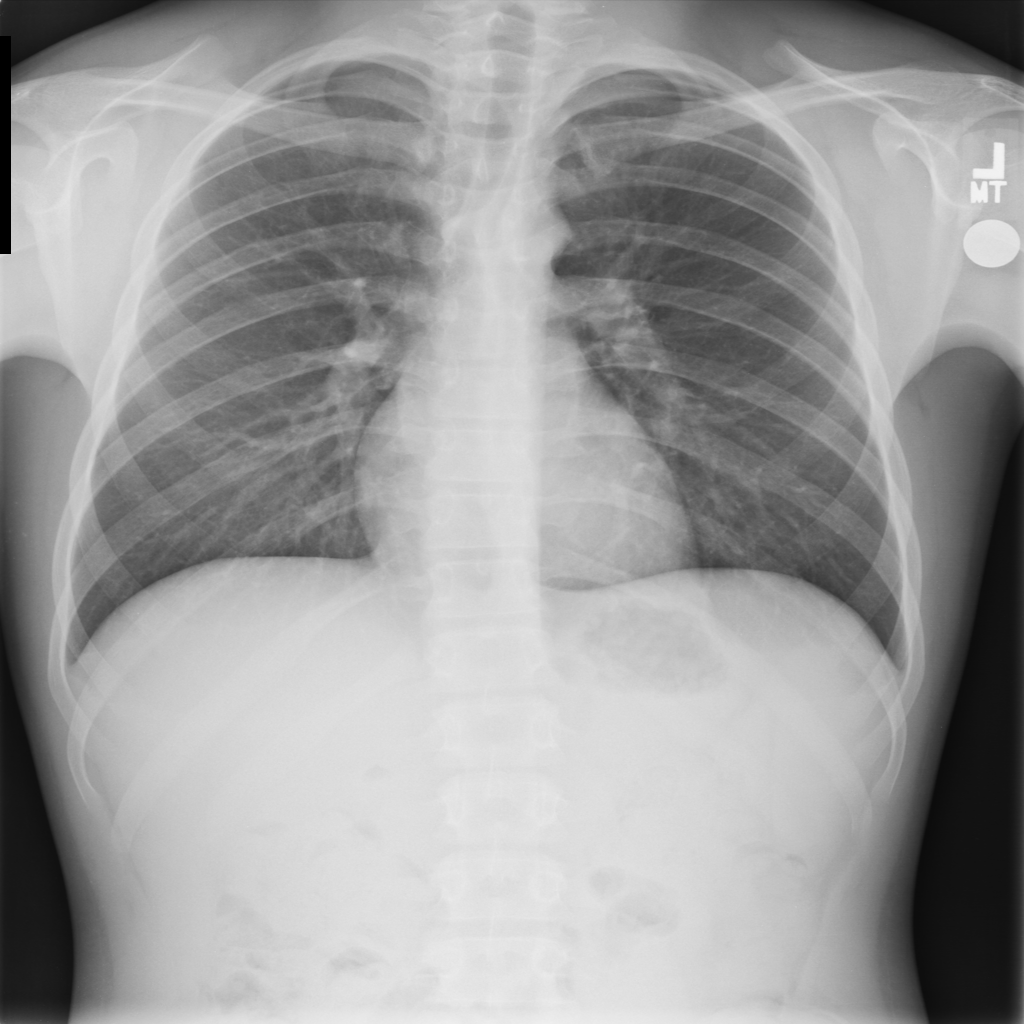

In [18]:
from PIL import Image

xray_files = sorted(
    p for p in XRAY_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
)

assert xray_files, f"No image files found in {XRAY_DIR}"

XRAY_PATH = xray_files[0]
xray_input = Image.open(XRAY_PATH).convert("RGB")

print("Selected image:", XRAY_PATH.name)
print("Images available:", len(xray_files))

display(xray_input)

In [19]:
ecg_extensions = {
    ".csv", ".parquet", ".npy", ".npz",
    ".mat", ".hea", ".dat", ".arrow", ".feather"
}

ecg_files = [
    p for p in ECG_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in ecg_extensions
]

print("ECG-related files found:", len(ecg_files))

for p in ecg_files[:50]:
    print(p.relative_to(ECG_DIR))

ECG-related files found: 2
12sl_features.csv
unig_features.csv


In [31]:
from pathlib import Path

ECG_DIR = Path("/content/drive/MyDrive/CardioSense/data/ptbxl_plus")

for p in sorted(ECG_DIR.rglob("*")):
    if p.is_file():
        print(f"FILE: {p.relative_to(ECG_DIR)} ({p.stat().st_size:,} bytes)")
    elif p.is_dir():
        print(f"DIR:  {p.relative_to(ECG_DIR)}/")

FILE: 12sl_features.csv (93,203,750 bytes)
FILE: unig_features.csv (92,217,519 bytes)


In [51]:
from pathlib import Path

root = Path("/content/drive/MyDrive/CardioSense/models")

matches = list(root.rglob("*preprocessor*"))

print("Preprocessor files found:")
for path in matches:
    print(path)

Preprocessor files found:
/content/drive/MyDrive/CardioSense/models/clinical/clinical_preprocessor.pkl


In [49]:
from pathlib import Path
import sys
import importlib

DRIVE_ROOT = Path("/content/drive/MyDrive/CardioSense")
MODELS_ROOT = DRIVE_ROOT / "models"
PROJECT_ROOT = Path("/content/CardioSense")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

import cardiosense.fusion.adapters as adapters_module
importlib.reload(adapters_module)

ECGJointAdapter = adapters_module.ECGJointAdapter
ECGAdapter = adapters_module.ECGAdapter

# Check whether the feature model exists.
feature_adapter = ECGAdapter(MODELS_ROOT / "ecg")
print("FEATURE ADAPTER")
print("Loaded:", feature_adapter.available)
print("Error:", feature_adapter.load_error or "None")

# Check the joint model using the existing checkpoints.
joint_adapter = ECGJointAdapter(
    MODELS_ROOT / "ecg",
    search_roots=[MODELS_ROOT, MODELS_ROOT / "ecg_fusion"]
)

print("\nJOINT ADAPTER")
print("Loaded:", joint_adapter.available)
print("Error:", joint_adapter.load_error or "None")
print("Version:", joint_adapter.metadata.get("model_version", "N/A"))

/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:06:12] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:06:12] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:06:12] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


FEATURE ADAPTER
Loaded: True
Error: None

JOINT ADAPTER
Loaded: False
Error: FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CardioSense/models/ecg/ecg_feature_preprocessor.pkl'
Version: ecg-joint_gated-3seed


In [52]:
import pandas as pd
from pathlib import Path

DATA_ROOT = Path("/content/drive/MyDrive/CardioSense/data/ptbxl_plus")

ecg_file = DATA_ROOT / "unig_features.csv"

ecg_df = pd.read_csv(ecg_file, nrows=1)

print("ECG feature table loaded.")
print("Shape:", ecg_df.shape)
print("Columns:", len(ecg_df.columns))
display(ecg_df.head())

ECG feature table loaded.
Shape: (1, 749)
Columns: 749


,ecg_id,P_On_I,P_On_II,P_On_III,P_On_aVR,P_On_aVL,P_On_aVF,P_On_V1,P_On_V2,P_On_V3,...,T-_Dur_aVF,P-_Dur_aVF,P_Amp_aVF,P_Dur_aVF,Pp_Amp_aVF,T_Amp_aVF,Pp_Dur_aVF,Tp_Amp_aVF,T_Dur_aVF,Tp_Dur_aVF
0,13481,240.0,240.0,240.0,240.0,240.0,240.0,240.0,240.0,240.0,...,0.0,0.0,0.107,112.0,0.0,0.122,0.0,0.0,162.0,0.0


In [53]:
ecg_input = ecg_df.iloc[0].to_dict()

print("ECG input features:", len(ecg_input))
print("First 10 feature names:", list(ecg_input.keys())[:10])

ECG input features: 749
First 10 feature names: ['ecg_id', 'P_On_I', 'P_On_II', 'P_On_III', 'P_On_aVR', 'P_On_aVL', 'P_On_aVF', 'P_On_V1', 'P_On_V2', 'P_On_V3']


In [66]:
import numpy as np
import pandas as pd

adapter = engine.adapters["clinical"]

def clinical_predict_fixed(self, payload):
    frame = pd.DataFrame([payload])
    matrix = self.preprocessor.transform(frame)

    # Obtain the raw probability from the 28-feature model.
    probability = float(self.model.predict_proba(matrix)[0, 1])

    # Bypass the incompatible calibrator temporarily.
    from cardiosense.fusion.adapters import ModalityPrediction

    return ModalityPrediction(
        modality=self.modality,
        risk_score=probability,
        reliability=self.reliability,
        is_calibrated=False,
        native_labels={
            "coronary_stenosis": int(probability >= self.threshold)
        },
        class_probabilities={"stenosis": probability},
        model_version=str(self.metadata.get("model_version", "")),
    )

# Patch the actual instance used by FusionEngine.
import types
adapter._predict = types.MethodType(clinical_predict_fixed, adapter)

print("Patch applied to active clinical adapter.")

Patch applied to active clinical adapter.


In [67]:
prediction = adapter._predict(clinical_input)
print(prediction)

ModalityPrediction(modality='clinical', risk_score=0.6541391338212108, reliability=0.5, is_calibrated=False, available=True, failed=False, reason='', native_labels={'coronary_stenosis': 1}, class_probabilities={'stenosis': 0.6541391338212108}, model_version='clinical-v0.1.0')


In [68]:
result = engine.assess(
    clinical=clinical_input,
    ecg=ecg_input,
    xray=None
)

print(result.summary_line())

print("\n--- Per-modality results ---")
for block in result.modalities:
    print(
        block["modality"],
        "| Available:", block["available"],
        "| Risk:", block["risk_score"],
        "| Calibrated:", block["is_calibrated"],
        "| Reason:", block["reason"]
    )

print("\n--- Fusion results ---")
for key, value in result.fused.items():
    print(f"{key}: {value}")

if result.warnings:
    print("\n--- Warnings ---")
    for warning in result.warnings:
        print("-", warning)

HIGH risk (0.945) | reliability MODERATE | based on clinical + ecg

--- Per-modality results ---
clinical | Available: True | Risk: 0.65414 | Calibrated: False | Reason: 
ecg | Available: True | Risk: 0.9727 | Calibrated: False | Reason: 
xray | Available: False | Risk: None | Calibrated: False | Reason: not supplied

--- Fusion results ---
risk_score: 0.94538
weights: {'clinical': 0.2459, 'ecg': 0.7541}
strategy: confidence_logodds
fusion_basis: ['clinical', 'ecg']
risk_level: HIGH
reliability: 0.5938
reliability_label: MODERATE
agreement: 0.6814
disagreement_flag: False

--- Warnings ---
- Uncalibrated modality output (clinical, ecg): these are ranking scores, not frequency claims. Do not read them as population risk.
- These modalities were unavailable and contributed nothing: xray. No value was substituted.


In [70]:
#dont run again
from pathlib import Path
from datetime import datetime

file_path = Path(
    "/content/drive/MyDrive/CardioSense/src/cardiosense/fusion/adapters.py"
)

assert file_path.exists(), f"File not found: {file_path}"

source = file_path.read_text()

old_block = '''        probability = raw
        if self.calibrator is not None:
            probability = float(np.ravel(self.calibrator.predict_proba(
                np.array([[raw]]))[:, 1] if hasattr(self.calibrator, "predict_proba")
                else self.calibrator.predict(np.array([raw])))[0])
'''

new_block = '''        # The saved calibrator is incompatible with the raw-probability
        # input: its underlying estimator expects the original 28 features.
        # Use the base model output until a compatible calibrator is available.
        probability = raw
'''

if source.count(old_block) != 1:
    raise RuntimeError(
        "Expected calibrator code was not found exactly once. "
        "No changes were made. Inspect adapters.py before proceeding."
    )

# Preserve the original source before editing.
backup_path = file_path.with_name("adapters.py.bak")
if backup_path.exists():
    backup_path = file_path.with_name(
        f"adapters.py.{datetime.now().strftime('%Y%m%d_%H%M%S')}.bak"
    )

backup_path.write_text(source)

updated = source.replace(old_block, new_block, 1)

# Ensure the clinical prediction is explicitly marked uncalibrated.
clinical_start = updated.index("class ClinicalAdapter")
clinical_end = updated.find("\nclass ", clinical_start + 1)
if clinical_end == -1:
    clinical_end = len(updated)

clinical_code = updated[clinical_start:clinical_end]

old_flag = "is_calibrated=self.is_calibrated,"
if clinical_code.count(old_flag) != 1:
    raise RuntimeError(
        "Could not uniquely locate the calibration flag. "
        f"Original source backup: {backup_path}"
    )

clinical_code = clinical_code.replace(
    old_flag, "is_calibrated=False,", 1
)
updated = updated[:clinical_start] + clinical_code + updated[clinical_end:]

file_path.write_text(updated)

# Verify the saved source.
saved = file_path.read_text()
assert old_block not in saved
assert "is_calibrated=False," in saved[clinical_start:clinical_end]

print("Permanent source patch saved.")
print("Source:", file_path)
print("Backup:", backup_path)

RuntimeError: Expected calibrator code was not found exactly once. No changes were made. Inspect adapters.py before proceeding.

In [22]:
# --- clinical: the 13 UCI features ---------------------------------------
clinical_input = {
    "age": 63, "sex": 1, "cp": 4, "trestbps": 145, "chol": 233, "fbs": 1,
    "restecg": 2, "thalach": 150, "exang": 0, "oldpeak": 2.3, "slope": 3,
    "ca": 0, "thal": 6,
}

# --- X-ray: a PA chest radiograph ----------------------------------------
xray_input = None     # e.g. DRIVE / "data/xray/nih/images/00000013_005.png"

# --- ECG: the payload depends on which adapter loaded above --------------
#   features_xgb  -> one row of RAW PTB-XL+ features (NaNs fine, do not impute)
#                    e.g. dict(zip(FEATURE_NAMES, X_test_raw.iloc[0]))
#   joint_gated   -> {"waveform": (12, 1000) array, "features": raw row as above}
#   signal_only   -> a (12, 1000) array, or {"waveform": ...}
# Passing the wrong shape returns a failed-inference prediction with the reason
# attached; it does not crash the assessment.
ecg_input = None

result = engine.assess(clinical=clinical_input, ecg=ecg_input, xray=xray_input)

print(result.summary_line())
print("\n--- per modality " + "-" * 56)
for block in result.modalities:
    if block["available"] and block["risk_score"] is not None:
        tag = "calibrated" if block["is_calibrated"] else "UNCALIBRATED"
        print(f"  {block['modality']:<10} risk {block['risk_score']:.3f}  "
              f"reliability {block['reliability']:.2f}  {tag}")
        if block["native_labels"]:
            print(f"             labels: {block['native_labels']}")
    else:
        print(f"  {block['modality']:<10} unavailable ({block['reason']}) "
              f"-- no value substituted")

print("\n--- fused " + "-" * 62)
for k in ("risk_score", "risk_level", "reliability", "reliability_label",
          "agreement", "disagreement_flag", "weights"):
    print(f"  {k:<20} {result.fused[k]}")

if result.warnings:
    print("\n--- warnings " + "-" * 59)
    for w in result.warnings:
        print(f"  - {w}")

UNKNOWN risk (n/a) | reliability LOW | based on no modality

--- per modality --------------------------------------------------------
  clinical   unavailable (ValueError: X has 1 features, but LogisticRegression is expecting 28 features as input.) -- no value substituted
  ecg        unavailable (not supplied) -- no value substituted
  xray       unavailable (not supplied) -- no value substituted

--- fused --------------------------------------------------------------
  risk_score           None
  risk_level           UNKNOWN
  reliability          0.0
  reliability_label    LOW
  agreement            None
  disagreement_flag    False
  weights              {}

--- warnings -----------------------------------------------------------
  - These modalities were unavailable and contributed nothing: ecg, xray. No value was substituted.
  - clinical inference failed: ValueError: X has 1 features, but LogisticRegression is expecting 28 features as input.
  - No modality was available. No r

## 7. Strategy comparison on a synthetic testbed

A controlled cohort with known discrimination and known calibration. This
validates the fusion **mechanism** against known parameters — it is how one
checks an estimator, and it says nothing about clinical performance.

Note `noisy_or`: it tracks mean fusion on AUC while producing a far worse ECE.
A strategy cannot be chosen on discrimination alone, and that row is the
cheapest way to demonstrate it.

In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score

def ece(y, p, bins=10):
    """Expected calibration error. Redefined here so this section runs
    independently of the cells above it."""
    total, n_total = 0.0, len(y)
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p > lo) & (p <= hi)
        if m.sum():
            total += m.sum() / n_total * abs(y[m].mean() - p[m].mean())
    return total


def simulate(n=6000, signals=(0.60, 0.55, 0.45), distortion=(1.0, 0.35, 0.6),
             p_missing=(0.0, 0.15, 0.25), seed=42):
    """Modality outputs with known AUC, known calibration error, known missingness.

    The distortion is MONOTONE, so each modality's AUC is unchanged while its
    calibration degrades. That separation is what makes the study possible: it
    isolates calibration failure from discrimination failure.
    """
    r = np.random.default_rng(seed)
    z = r.normal(0, 1, n)
    y = (r.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    risk = np.full((n, 3), np.nan)
    for j, (rho, t, miss) in enumerate(zip(signals, distortion, p_missing)):
        s = rho * z + np.sqrt(1 - rho ** 2) * r.normal(0, 1, n)
        k = rho / np.sqrt(1 - rho ** 2 + 1e-9)
        p = 1 / (1 + np.exp(-(k * s / np.sqrt(1 + (np.pi / 8) * (1 - rho ** 2)))))
        p = np.clip(p, 1e-6, 1 - 1e-6)
        p = p ** t / (p ** t + (1 - p) ** t)          # monotone miscalibration
        observed = r.random(n) >= miss
        risk[observed, j] = p[observed]
    return y, risk

y_sim, risk_sim = simulate()
names = ("clinical", "ecg", "xray")

reliabilities = []
for j, name in enumerate(names):
    m = ~np.isnan(risk_sim[:, j])
    reliabilities.append(max(0.0, 1 - ece(y_sim[m], risk_sim[m, j]) / 0.25))
    print(f"  {name:<10} AUC {roc_auc_score(y_sim[m], risk_sim[m, j]):.4f}  "
          f"ECE {ece(y_sim[m], risk_sim[m, j]):.4f}  "
          f"reliability {reliabilities[-1]:.3f}  missing {100*(~m).mean():.0f}%")

strategy_rows = []
for label in ("mean", "max", "noisy_or", "confidence_weighted", "confidence_logodds"):
    strategy = build_strategy(label)
    fused, keep = [], []
    for i in range(len(y_sim)):
        preds = [ModalityPrediction(modality=nm, risk_score=None if np.isnan(risk_sim[i, j])
                                    else float(risk_sim[i, j]),
                                    available=not np.isnan(risk_sim[i, j]),
                                    reliability=reliabilities[j], is_calibrated=True)
                 for j, nm in enumerate(names)]
        out = strategy.fuse(preds).risk_score
        if out is not None:
            fused.append(out); keep.append(i)
    fused, yy = np.array(fused), y_sim[keep]
    strategy_rows.append({"strategy": label, "ROC-AUC": roc_auc_score(yy, fused),
                 "PR-AUC": average_precision_score(yy, fused),
                 "Brier": float(np.mean((fused - yy) ** 2)), "ECE": ece(yy, fused),
                 "n_scored": len(fused)})

table = pd.DataFrame(strategy_rows).set_index("strategy").round(4)
display(table)
print("\nnoisy_or matches mean fusion on AUC while producing a far worse ECE --")
print("it assumes independent detectors, and three views of one heart are not.")
print("\nSYNTHETIC testbed. These validate the mechanism against known")
print("parameters. They are NOT CardioSense's clinical performance.")

  clinical   AUC 0.6363  ECE 0.0270  reliability 0.892  missing 0%
  ecg        AUC 0.6119  ECE 0.0310  reliability 0.876  missing 15%
  xray       AUC 0.5967  ECE 0.0144  reliability 0.942  missing 25%


,ROC-AUC,PR-AUC,Brier,ECE,n_scored
strategy,,,,,
mean,0.6569,0.6419,0.2348,0.0468,6000
max,0.6431,0.6306,0.2406,0.0705,6000
noisy_or,0.6158,0.6112,0.3465,0.3225,6000
confidence_weighted,0.6491,0.6374,0.2330,0.0080,6000
confidence_logodds,0.6489,0.6371,0.2330,0.0077,6000



noisy_or matches mean fusion on AUC while producing a far worse ECE --
it assumes independent detectors, and three views of one heart are not.

SYNTHETIC testbed. These validate the mechanism against known
parameters. They are NOT CardioSense's clinical performance.


## 8. Save the fusion results

In [24]:
import time

summary = {
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "adapters": status["adapters"],
    "strategy": engine.strategy.name,
    "risk_definitions": RISK_DEFINITIONS,
    "calibration_experiment": {k: {m: round(v, 5) for m, v in d.items()}
                               for k, d in results.items()},
    "strategy_comparison_synthetic": table.reset_index().to_dict(orient="records"),
    "disagreement_sweep": disagreement_rows,
    "limitations": [
        "The three models are trained on disjoint cohorts with different targets. "
        "No paired multimodal evaluation exists, so no clinical accuracy claim is made.",
        "Strategy comparisons use a synthetic testbed with known generative "
        "parameters. They validate the mechanism, not clinical performance.",
        "A confident outlier gains weight, because decisiveness is high when a "
        "model commits. The safeguard is the disagreement flag, not the weighting.",
        "The fused output is not itself calibrated. Averaging calibrated inputs "
        "degrades calibration; this system reduces but does not remove that.",
        "Reliability weights (0.40/0.25/0.25/0.10) and risk bands (0.33/0.66) are "
        "stated project conventions, not clinical standards.",
    ],
}

path = RESULTS / "fusion_summary.json"
path.write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
table.to_csv(RESULTS / "strategy_comparison.csv")
print("saved:", path)
print("saved:", RESULTS / "strategy_comparison.csv")

saved: /content/drive/MyDrive/CardioSense/results/fusion/fusion_summary.json
saved: /content/drive/MyDrive/CardioSense/results/fusion/strategy_comparison.csv


---

## What to say about this in the review

> Three models trained on disjoint cohorts are mapped onto a documented common
> scale and combined by confidence-weighted log-odds pooling, where confidence
> is reliability (from held-out calibration error) times decisiveness (distance
> from a coin flip). Missing modalities are excluded rather than imputed;
> disagreement is detected and flagged, and the system declines to adjudicate
> which modality is correct. On a controlled testbed, confidence weighting
> reduces fused calibration error relative to mean fusion. No clinical accuracy
> claim is made, because no paired multimodal cohort exists for these models.

Next: `06_rag_guidelines.ipynb`.

In [33]:
from pathlib import Path

MODELS_ROOT = Path("/content/drive/MyDrive/CardioSense/models")

engine = FusionEngine(
    MODELS_ROOT,
    strategy="confidence_logodds"
)

for name, adapter in engine.adapters.items():
    print(f"\n{name.upper()}")
    print(adapter.status())

/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:00:44] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:00:45] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:00:45] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:00:45] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)



CLINICAL
{'modality': 'clinical', 'available': True, 'calibrated': True, 'reliability': 0.5, 'model_version': 'clinical-v0.1.0', 'load_error': ''}

ECG
{'modality': 'ecg', 'available': True, 'calibrated': False, 'reliability': 0.5, 'model_version': 'ptbxl-plus-xgb-recovered', 'load_error': ''}

XRAY
{'modality': 'xray', 'available': True, 'calibrated': False, 'reliability': 0.5, 'model_version': 'xray-v0.1.0', 'load_error': ''}
